**For generating plots using Wandb csv.file**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import numpy as np

def find_columns(df, keyword, metric_type='success_rate', exclude=None):
    target_pattern = f'mean_{metric_type}'
    cols = []
    
    # 비교를 위해 키워드에서 언더스코어 제거 및 소문자화
    clean_kw = keyword.lower().replace('_', '')
    
    for col in df.columns:
        col_lower = col.lower()
        clean_col = col_lower.replace('_', '')
        
        # 키워드와 패턴이 모두 포함되어 있는지 확인
        if clean_kw in clean_col and target_pattern.lower() in col_lower:
            if 'MIN' in col or 'MAX' in col or '_step' in col:
                continue
            
            # exclude 키워드 확인
            if exclude and exclude.lower() in col_lower:
                continue
                
            cols.append(col)
    return cols

def plot(models_config, base_path='wandb_csv/SH/', window_size=50):
    plt.rc('font', size=12)
    plt.rc('axes', labelsize=12)
    plt.rc('xtick', labelsize=12)
    plt.rc('ytick', labelsize=12)
    plt.rc('legend', fontsize=12)
    
    metrics = [
        ('success_rate', 'Success Rate'),
        # ('episode_reward', 'Mean Episode Return')
    ]
    
    for metric_type, metric_label in metrics:
        plt.figure(figsize=(8,6))
        
        for label, config in models_config.items():
            kw = config['keyword']
            exc = config.get('exclude')
            color = config['color']
            
            # 파일 경로 생성
            file_name = f"sh3_{kw}.csv"
            file_path = os.path.join(base_path, file_name)
            
            if not os.path.exists(file_path):
                print(f"Warning: File not found {file_path}. Skipping {label}.")
                continue
                
            df = pd.read_csv(file_path)
            
            # 해당 metric의 모든 seed 컬럼 찾기
            cols = find_columns(df, kw, metric_type, exclude=exc)
            
            if cols:
                # 모든 seed 컬럼의 row-wise 평균과 표준편차 계산
                x = df['total_steps']
                data = df[cols]
                
                # Cross-seed mean and std
                y_mean_raw = data.mean(axis=1)
                y_std_raw = data.std(axis=1)
                
                # Smoothing (rolling mean)
                y_mean = y_mean_raw.rolling(window=window_size, min_periods=1).mean()
                y_std = y_std_raw.rolling(window=window_size, min_periods=1).mean()
                
                plt.plot(x, y_mean, label=label, color=color, linewidth=2)
                plt.fill_between(x, y_mean - y_std, y_mean + y_std, color=color, alpha=0.15)
            else:
                print(f"No columns found for {label} in {file_path}")

        plt.title(metric_label)
        plt.xlabel('Total Steps')
        plt.ylabel(metric_label)
        plt.legend(loc='lower center', bbox_to_anchor=(0.5, 1.05), ncol=4, frameon=False)
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()

def plot_causal_effect(file_path, window_size=50):
    try:
        df = pd.read_csv(file_path)
    except FileNotFoundError:
        print(f'File not found: {file_path}')
        return
    plt.rc('font', size=10)
    plt.rc('axes', labelsize=12)
    plt.rc('xtick', labelsize=10)
    plt.rc('ytick', labelsize=10)
    plt.rc('legend', fontsize=10)
    
    reward_type = None
    target_cols = []
    
    stag_cols = [c for c in df.columns if 'delta_stag_reward' in c and 'agent' in c and 'MIN' not in c and 'MAX' not in c]
    if stag_cols:
        reward_type = 'Stag'
        target_cols = stag_cols
    else:
        forage_cols = [c for c in df.columns if 'delta_forage_reward' in c and 'agent' in c and 'MIN' not in c and 'MAX' not in c]
        if forage_cols:
            reward_type = 'Forage'
            target_cols = forage_cols
    
    if not target_cols:
        print(f'No suitable columns found in {file_path}')
        return

    print(f"Plotting {reward_type} Causal Effect from: {file_path}")
    df['mean_agent_reward'] = df[target_cols].mean(axis=1)
    
    x = df['total_steps']
    y = df['mean_agent_reward']
    
    y_mean = y.rolling(window=window_size, min_periods=1).mean()
    y_std = y.rolling(window=window_size, min_periods=1).std()
    
    plt.figure(figsize=(10, 6))
    plt.plot(x, y_mean, label=f'Average $\\delta$_{reward_type}', linewidth=2)
    plt.fill_between(x, y_mean - y_std, y_mean + y_std, alpha=0.2)
    plt.title(f'Causal Effect: Average $\\delta$_{reward_type} over agents')
    plt.ylim(bottom=0)
    plt.xlabel('Total Steps')
    plt.ylabel(f'Delta {reward_type} Reward')
    plt.legend()
    plt.grid(True, linestyle= '--', alpha=0.5)
    plt.show()

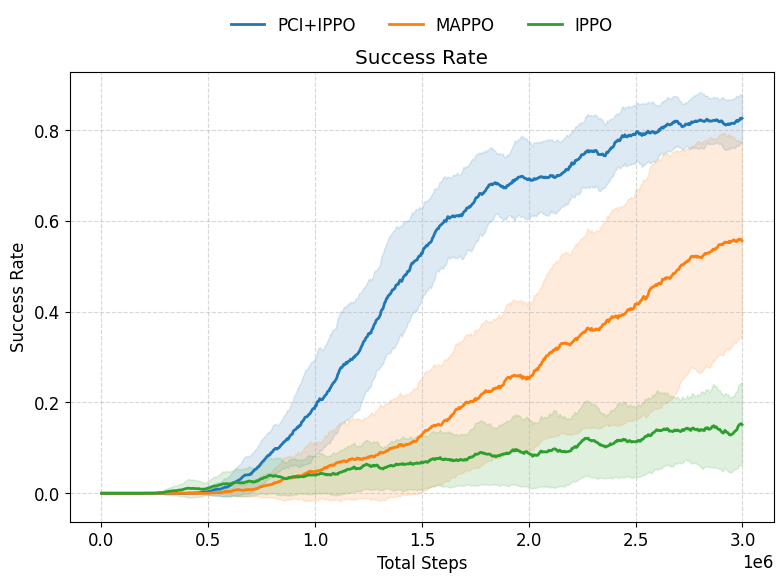

File not found: wandb_csv/sh3_stag_causal_effect.csv
File not found: wandb_csv/sh3_forage_causal_effect.csv


In [2]:
# 모델 설정: 'exclude' 옵션을 사용하여 특정 환경 이름 없이 구분
models_config = {
    "PCI+IPPO":  {"keyword": "PCI_rIPPO", "color": "tab:blue"},
    "PCI+MAPPO": {"keyword": "PCI_rMAPPO", "color": "tab:skyblue"},
    "MAPPO":      {"keyword": "rMAPPO", "exclude": "pci", "color": "tab:orange"}, # 'pci'가 없는 'mappo'만 선택
    "IPPO":       {"keyword": "rIPPO", "exclude": "pci", "color": "tab:green"},
}

# Plotting
plot(models_config, base_path='wandb_csv/SH/', window_size=20)
plot_causal_effect('wandb_csv/sh3_stag_causal_effect.csv')
plot_causal_effect('wandb_csv/sh3_forage_causal_effect.csv')